In [47]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [48]:
!pip install scikit-image

In [49]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from skimage.metrics import peak_signal_noise_ratio as psnr
from tqdm import tqdm
import glob

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
print(f"PyTorch version: {torch.__version__}")


Using device: cpu
PyTorch version: 2.8.0+cu126


In [50]:
!mkdir -p /content/DIV2K
# adjust these paths to where your zip files are
!unzip -q "/content/drive/MyDrive/DIV2K/DIV2K_train_HR.zip" -d /content/DIV2K/train_hr
!unzip -q "/content/drive/MyDrive/DIV2K/DIV2K_valid_HR.zip" -d /content/DIV2K/valid_hr

replace /content/DIV2K/train_hr/DIV2K_train_HR/0103.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: N
replace /content/DIV2K/valid_hr/DIV2K_valid_HR/0897.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: N


In [60]:
class Config:
    # Data parameters
    HR_SIZE = 224  # High-resolution image size
    CROP_SIZE = 800  # Initial crop size before downsizing

    # Dataset splits (using 100 images as per project spec)
    NUM_TRAIN = 60
    NUM_VAL = 20
    NUM_TEST = 20

    # Training parameters
    BATCH_SIZE = 2  # Limited by GPU memory as noted in project
    LEARNING_RATE = 0.001  # Optimal LR from project findings
    NUM_EPOCHS = 75

    # Model parameters
    PATCH_SIZE = 9
    MAPPING_SIZE = 1
    RECON_SIZE = 5
    NUM_CHANNELS_1 = 64
    NUM_CHANNELS_2 = 32

    # Paths (adjust these to your DIV2K dataset location)
    TRAIN_HR_PATH = '/content/DIV2K/train_hr/DIV2K_train_HR' # Update this path
    VAL_HR_PATH = "/content/DIV2K/valid_hr/DIV2K_valid_HR" # Update this path

    # Output
    SAVE_MODEL_PATH = '/content/srcnn_best_model.pth'

config = Config()
train_images = glob.glob(os.path.join(config.TRAIN_HR_PATH, '*.png'))
val_images = glob.glob(os.path.join(config.VAL_HR_PATH, '*.png'))
print(f"Train HR images found: {len(train_images)}")
print(f"Valid HR images found: {len(val_images)}")

Train HR images found: 800
Valid HR images found: 100


In [61]:
class SuperResolutionDataset(Dataset):
    """Dataset for Super-Resolution training"""

    def __init__(self, image_paths, hr_size=224, crop_size=800):
        self.image_paths = image_paths
        self.hr_size = hr_size
        self.crop_size = crop_size

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # Load high-resolution image
        img_path = self.image_paths[idx]
        hr_img = Image.open(img_path).convert('RGB')

        # Center crop to standard size
        hr_img = self.center_crop(hr_img, self.crop_size)

        # Resize to target HR size
        hr_img = hr_img.resize((self.hr_size, self.hr_size), Image.BICUBIC)

        # Generate low-resolution input
        # Step 1: Downsize to half
        lr_size = self.hr_size // 2
        lr_img = hr_img.resize((lr_size, lr_size), Image.BICUBIC)

        # Step 2: Upsize back to HR size (bilinear interpolation as per SRCNN preprocessing)
        lr_img_upsampled = lr_img.resize((self.hr_size, self.hr_size), Image.BILINEAR)

        # Convert to tensors
        hr_tensor = transforms.ToTensor()(hr_img)
        lr_tensor = transforms.ToTensor()(lr_img_upsampled)

        return lr_tensor, hr_tensor

    def center_crop(self, img, crop_size):
        """Center crop image to specified size"""
        width, height = img.size

        # If image is smaller than crop size, use the smaller dimension
        crop_size = min(crop_size, width, height)

        left = (width - crop_size) // 2
        top = (height - crop_size) // 2
        right = left + crop_size
        bottom = top + crop_size

        return img.crop((left, top, right, bottom))


In [62]:
def load_dataset_splits(train_path, val_path, num_train, num_val, num_test):
    """Load and split the DIV2K dataset"""

    # Get all training images
    train_images = sorted(glob.glob(os.path.join(train_path, '*.png')))

    # Get validation images (we'll use some for testing)
    val_images = sorted(glob.glob(os.path.join(val_path, '*.png')))

    # Verify we have enough images
    if len(train_images) < num_train + num_val:
        print(f"Warning: Not enough training images. Found {len(train_images)}, need {num_train + num_val}")
        print(f"Adjusting splits...")
        num_train = min(num_train, len(train_images) * 3 // 5)
        num_val = min(num_val, len(train_images) - num_train)

    if len(val_images) < num_test:
        print(f"Warning: Not enough validation images. Found {len(val_images)}, need {num_test}")
        num_test = min(num_test, len(val_images))

    # Split according to specification
    train_split = train_images[:num_train]
    val_split = train_images[num_train:num_train + num_val]
    test_split = val_images[:num_test]

    print(f"Dataset splits:")
    print(f"  Training: {len(train_split)} images")
    print(f"  Validation: {len(val_split)} images")
    print(f"  Testing: {len(test_split)} images")

    return train_split, val_split, test_split

In [63]:
class SRCNN(nn.Module):
    """
    Super-Resolution Convolutional Neural Network (SRCNN)
    Three-layer architecture: Patch Extraction -> Non-linear Mapping -> Reconstruction
    """

    def __init__(self, num_channels=3):
        super(SRCNN, self).__init__()

        # Layer 1: Patch Extraction
        self.conv1 = nn.Conv2d(num_channels, config.NUM_CHANNELS_1,
                               kernel_size=config.PATCH_SIZE, padding=config.PATCH_SIZE//2)
        self.relu1 = nn.ReLU(inplace=True)

        # Layer 2: Non-linear Mapping
        self.conv2 = nn.Conv2d(config.NUM_CHANNELS_1, config.NUM_CHANNELS_2,
                               kernel_size=config.MAPPING_SIZE, padding=config.MAPPING_SIZE//2)
        self.relu2 = nn.ReLU(inplace=True)

        # Layer 3: Reconstruction
        self.conv3 = nn.Conv2d(config.NUM_CHANNELS_2, num_channels,
                               kernel_size=config.RECON_SIZE, padding=config.RECON_SIZE//2)

    def forward(self, x):
        x = self.relu1(self.conv1(x))
        x = self.relu2(self.conv2(x))
        x = self.conv3(x)
        return x

In [64]:
def calculate_psnr(img1, img2):
    """Calculate PSNR between two images"""
    img1_np = img1.detach().cpu().numpy().transpose(1, 2, 0)
    img2_np = img2.detach().cpu().numpy().transpose(1, 2, 0)
    return psnr(img1_np, img2_np, data_range=1.0)

def train_epoch(model, dataloader, criterion, optimizer, device):
    """Train for one epoch"""
    model.train()
    running_loss = 0.0
    running_psnr = 0.0

    for lr_imgs, hr_imgs in tqdm(dataloader, desc="Training"):
        lr_imgs = lr_imgs.to(device)
        hr_imgs = hr_imgs.to(device)

        # Forward pass
        optimizer.zero_grad()
        sr_imgs = model(lr_imgs)

        # Calculate loss
        loss = criterion(sr_imgs, hr_imgs)

        # Backward pass
        loss.backward()
        optimizer.step()

        # Track metrics
        running_loss += loss.item()

        # Calculate PSNR for this batch
        for i in range(sr_imgs.size(0)):
            running_psnr += calculate_psnr(sr_imgs[i], hr_imgs[i])

    avg_loss = running_loss / len(dataloader)
    avg_psnr = running_psnr / len(dataloader.dataset)

    return avg_loss, avg_psnr

def validate(model, dataloader, criterion, device):
    """Validate the model"""
    model.eval()
    running_loss = 0.0
    running_psnr = 0.0

    with torch.no_grad():
        for lr_imgs, hr_imgs in tqdm(dataloader, desc="Validating"):
            lr_imgs = lr_imgs.to(device)
            hr_imgs = hr_imgs.to(device)

            # Forward pass
            sr_imgs = model(lr_imgs)

            # Calculate loss
            loss = criterion(sr_imgs, hr_imgs)
            running_loss += loss.item()

            # Calculate PSNR
            for i in range(sr_imgs.size(0)):
                running_psnr += calculate_psnr(sr_imgs[i], hr_imgs[i])

    avg_loss = running_loss / len(dataloader)
    avg_psnr = running_psnr / len(dataloader.dataset)

    return avg_loss, avg_psnr

def calculate_bicubic_baseline(dataloader, device):
    """Calculate baseline PSNR for bicubic upsampling"""
    psnr_values = []

    with torch.no_grad():
        for lr_imgs, hr_imgs in tqdm(dataloader, desc="Bicubic Baseline"):
            for i in range(lr_imgs.size(0)):
                psnr_val = calculate_psnr(lr_imgs[i], hr_imgs[i])
                psnr_values.append(psnr_val)

    return np.mean(psnr_values)

In [65]:
def visualize_results(model, dataloader, device, num_samples=3):
    """Visualize super-resolution results"""
    model.eval()

    samples = []
    with torch.no_grad():
        for lr_imgs, hr_imgs in dataloader:
            lr_imgs = lr_imgs.to(device)
            hr_imgs = hr_imgs.to(device)
            sr_imgs = model(lr_imgs)

            for i in range(min(lr_imgs.size(0), num_samples - len(samples))):
                samples.append((lr_imgs[i].cpu(), sr_imgs[i].cpu(), hr_imgs[i].cpu()))

            if len(samples) >= num_samples:
                break

    fig, axes = plt.subplots(num_samples, 3, figsize=(15, 5*num_samples))

    for i, (lr, sr, hr) in enumerate(samples):
        # Convert tensors to images
        lr_img = lr.numpy().transpose(1, 2, 0)
        sr_img = sr.numpy().transpose(1, 2, 0)
        hr_img = hr.numpy().transpose(1, 2, 0)

        # Clip values to valid range
        lr_img = np.clip(lr_img, 0, 1)
        sr_img = np.clip(sr_img, 0, 1)
        hr_img = np.clip(hr_img, 0, 1)

        # Calculate PSNR
        lr_psnr = psnr(lr_img, hr_img, data_range=1.0)
        sr_psnr = psnr(sr_img, hr_img, data_range=1.0)

        axes[i, 0].imshow(lr_img)
        axes[i, 0].set_title(f'Bicubic Input\nPSNR: {lr_psnr:.2f} dB')
        axes[i, 0].axis('off')

        axes[i, 1].imshow(sr_img)
        axes[i, 1].set_title(f'SRCNN Output\nPSNR: {sr_psnr:.2f} dB')
        axes[i, 1].axis('off')

        axes[i, 2].imshow(hr_img)
        axes[i, 2].set_title('Ground Truth (HR)')
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()


In [66]:
def main():
    """Main training and evaluation pipeline"""

    print("="*80)
    print("SRCNN Image Super-Resolution Project")
    print("="*80)

    # Load dataset
    print("\n1. Loading and splitting dataset...")
    train_paths, val_paths, test_paths = load_dataset_splits(
        config.TRAIN_HR_PATH,
        config.VAL_HR_PATH,
        config.NUM_TRAIN,
        config.NUM_VAL,
        config.NUM_TEST
    )




    # Create datasets
    train_dataset = SuperResolutionDataset(train_paths, config.HR_SIZE, config.CROP_SIZE)
    val_dataset = SuperResolutionDataset(val_paths, config.HR_SIZE, config.CROP_SIZE)
    test_dataset = SuperResolutionDataset(test_paths, config.HR_SIZE, config.CROP_SIZE)

    # Create dataloaders
    train_loader = DataLoader(train_dataset, batch_size=config.BATCH_SIZE, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_dataset, batch_size=config.BATCH_SIZE, shuffle=False, num_workers=2)
    test_loader = DataLoader(test_dataset, batch_size=config.BATCH_SIZE, shuffle=False, num_workers=2)

    # Calculate bicubic baseline
    print("\n2. Calculating bicubic baseline PSNR...")
    baseline_psnr = calculate_bicubic_baseline(test_loader, device)
    print(f"   Bicubic baseline PSNR: {baseline_psnr:.3f} dB")
    print(f"   Target: Significantly exceed 23.226 dB")

    # Initialize model
    print("\n3. Initializing SRCNN model...")
    model = SRCNN().to(device)
    print(f"   Model parameters: {sum(p.numel() for p in model.parameters()):,}")

    # Loss function and optimizer
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=config.LEARNING_RATE)

    # Training history
    train_losses, val_losses = [], []
    train_psnrs, val_psnrs = [], []
    best_val_psnr = 0.0

    # Training loop
    print(f"\n4. Training for {config.NUM_EPOCHS} epochs...")
    print("-"*80)

    for epoch in range(config.NUM_EPOCHS):
        print(f"\nEpoch {epoch+1}/{config.NUM_EPOCHS}")

        # Train
        train_loss, train_psnr = train_epoch(model, train_loader, criterion, optimizer, device)
        train_losses.append(train_loss)
        train_psnrs.append(train_psnr)

        # Validate
        val_loss, val_psnr = validate(model, val_loader, criterion, device)
        val_losses.append(val_loss)
        val_psnrs.append(val_psnr)

        print(f"Train Loss: {train_loss:.6f}, Train PSNR: {train_psnr:.3f} dB")
        print(f"Val Loss: {val_loss:.6f}, Val PSNR: {val_psnr:.3f} dB")

        # Save best model
        if val_psnr > best_val_psnr:
            best_val_psnr = val_psnr
            torch.save(model.state_dict(), config.SAVE_MODEL_PATH)
            print(f"✓ Best model saved! (Val PSNR: {best_val_psnr:.3f} dB)")

    # Plot training history
   # print("\n5. Plotting training history...")
   # plot_training_history(train_losses, val_losses, train_psnrs, val_psnrs)

    # Load best model for testing
    print("\n6. Loading best model for final evaluation...")
    model.load_state_dict(torch.load(config.SAVE_MODEL_PATH))

    # Final test evaluation
    print("\n7. Final Test Set Evaluation...")
    test_loss, test_psnr = validate(model, test_loader, criterion, device)
    print(f"   Test Loss: {test_loss:.6f}")
    print(f"   Test PSNR: {test_psnr:.3f} dB")
    print(f"   Bicubic Baseline: {baseline_psnr:.3f} dB")
    print(f"   Improvement: {test_psnr - baseline_psnr:.3f} dB")

    # Visualize results
    print("\n8. Visualizing results...")
    visualize_results(model, test_loader, device, num_samples=3)

    # Summary
    print("\n" + "="*80)
    print("FINAL RESULTS SUMMARY")
    print("="*80)
    print(f"Bicubic Baseline PSNR:  {baseline_psnr:.3f} dB")
    print(f"SRCNN Test PSNR:        {test_psnr:.3f} dB")
    print(f"Improvement:            {test_psnr - baseline_psnr:.3f} dB")
    print(f"Target (from paper):    26.442 dB")
    print("="*80)


In [67]:
main()

Output hidden; open in https://colab.research.google.com to view.

In [33]:

import copy

# Store all experiment results
experiment_results = {}

def run_experiment(exp_name, model_class, config_overrides, num_epochs=100):
    """
    Run a single experiment with specific hyperparameters

    Args:
        exp_name: Name of the experiment
        model_class: Model class to use (SRCNN or variants)
        config_overrides: Dict of config parameters to override
        num_epochs: Number of epochs to train
    """
    print(f"\n{'='*80}")
    print(f"EXPERIMENT: {exp_name}")
    print(f"{'='*80}")

    # Create a copy of config
    exp_config = copy.deepcopy(config)

    # Apply overrides
    for key, value in config_overrides.items():
        setattr(exp_config, key, value)

    exp_config.NUM_EPOCHS = num_epochs

    # Load dataset (reuse existing splits)
    train_paths, val_paths, test_paths = load_dataset_splits(
        exp_config.TRAIN_HR_PATH,
        exp_config.VAL_HR_PATH,
        exp_config.NUM_TRAIN,
        exp_config.NUM_VAL,
        exp_config.NUM_TEST
    )

    # Create datasets
    train_dataset = SuperResolutionDataset(train_paths, exp_config.HR_SIZE, exp_config.CROP_SIZE)
    val_dataset = SuperResolutionDataset(val_paths, exp_config.HR_SIZE, exp_config.CROP_SIZE)

    # Create dataloaders
    train_loader = DataLoader(train_dataset, batch_size=exp_config.BATCH_SIZE, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_dataset, batch_size=exp_config.BATCH_SIZE, shuffle=False, num_workers=2)

    # Initialize model
    model = model_class().to(device)

    # Loss and optimizer
    criterion = nn.MSELoss()

    # Apply weight decay if specified
    if hasattr(exp_config, 'WEIGHT_DECAY'):
        optimizer = optim.Adam(model.parameters(), lr=exp_config.LEARNING_RATE,
                              weight_decay=exp_config.WEIGHT_DECAY)
    else:
        optimizer = optim.Adam(model.parameters(), lr=exp_config.LEARNING_RATE)

    # Training history
    train_losses, val_losses = [], []
    train_psnrs, val_psnrs = [], []
    best_val_psnr = 0.0

    # Training loop
    for epoch in range(exp_config.NUM_EPOCHS):
        # Train
        train_loss, train_psnr = train_epoch(model, train_loader, criterion, optimizer, device)
        train_losses.append(train_loss)
        train_psnrs.append(train_psnr)

        # Validate
        val_loss, val_psnr = validate(model, val_loader, criterion, device)
        val_losses.append(val_loss)
        val_psnrs.append(val_psnr)

        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{exp_config.NUM_EPOCHS} - "
                  f"Val PSNR: {val_psnr:.3f} dB")

        # Save best model
        if val_psnr > best_val_psnr:
            best_val_psnr = val_psnr

    # Store results
    experiment_results[exp_name] = {
        'train_losses': train_losses,
        'val_losses': val_losses,
        'train_psnrs': train_psnrs,
        'val_psnrs': val_psnrs,
        'best_val_psnr': best_val_psnr,
        'config': config_overrides
    }

    print(f"Best Validation PSNR: {best_val_psnr:.3f} dB")

    return experiment_results[exp_name]

In [44]:
class SRCNN_BatchNorm(nn.Module):
    """SRCNN with Batch Normalization (for Figure 5)"""
    def __init__(self, num_channels=3):
        super(SRCNN_BatchNorm, self).__init__()

        self.conv1 = nn.Conv2d(num_channels, config.NUM_CHANNELS_1,
                               kernel_size=config.PATCH_SIZE, padding=config.PATCH_SIZE//2)
        self.bn1 = nn.BatchNorm2d(config.NUM_CHANNELS_1)
        self.relu1 = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(config.NUM_CHANNELS_1, config.NUM_CHANNELS_2,
                               kernel_size=config.MAPPING_SIZE, padding=config.MAPPING_SIZE//2)
        self.bn2 = nn.BatchNorm2d(config.NUM_CHANNELS_2)
        self.relu2 = nn.ReLU(inplace=True)

        self.conv3 = nn.Conv2d(config.NUM_CHANNELS_2, num_channels,
                               kernel_size=config.RECON_SIZE, padding=config.RECON_SIZE//2)

    def forward(self, x):
        x = self.relu1(self.bn1(self.conv1(x)))
        x = self.relu2(self.bn2(self.conv2(x)))
        x = self.conv3(x)
        return x


class SRCNN_Tanh(nn.Module):
    """SRCNN with Tanh activation on output (for Figure 4)"""
    def __init__(self, num_channels=3):
        super(SRCNN_Tanh, self).__init__()

        self.conv1 = nn.Conv2d(num_channels, config.NUM_CHANNELS_1,
                               kernel_size=config.PATCH_SIZE, padding=config.PATCH_SIZE//2)
        self.relu1 = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(config.NUM_CHANNELS_1, config.NUM_CHANNELS_2,
                               kernel_size=config.MAPPING_SIZE, padding=config.MAPPING_SIZE//2)
        self.relu2 = nn.ReLU(inplace=True)

        self.conv3 = nn.Conv2d(config.NUM_CHANNELS_2, num_channels,
                               kernel_size=config.RECON_SIZE, padding=config.RECON_SIZE//2)
        self.tanh = nn.Tanh()

    def forward(self, x):
        x = self.relu1(self.conv1(x))
        x = self.relu2(self.conv2(x))
        x = self.tanh(self.conv3(x))
        return x

In [45]:

def run_figure3_experiments():
    """Run experiments for Figure 3: Learning rate comparison with baselines"""
    print("\n" + "="*80)
    print("RUNNING FIGURE 3 EXPERIMENTS: Learning Rate Comparison")
    print("="*80)

    # Baseline experiments (just evaluate, no training needed)
    print("\nCalculating baseline PSNRs...")

    # Run SRCNN with different learning rates
    learning_rates = [0.01, 0.001, 0.0001]

    for lr in learning_rates:
        run_experiment(
            f'lr_{lr}_no_bn',
            SRCNN,
            {'LEARNING_RATE': lr},
            num_epochs=25
        )

    print("\nFigure 3 experiments complete!")

In [46]:
def run_figure4_experiments():
    """Run experiments for Figure 4: Tanh activation comparison"""
    print("\n" + "="*80)
    print("RUNNING FIGURE 4 EXPERIMENTS: Tanh Activation")
    print("="*80)

    # Tanh variants
    learning_rates = [0.001, 0.0001]

    for lr in learning_rates:
        run_experiment(
            f'tanh_lr_{lr}',
            SRCNN_Tanh,
            {'LEARNING_RATE': lr},
            num_epochs=25
        )

    # Regular SRCNN for comparison
    for lr in learning_rates:
        run_experiment(
            f'lr_{lr}_no_bn',
            SRCNN,
            {'LEARNING_RATE': lr},
            num_epochs=25
        )

    print("\nFigure 4 experiments complete!")

In [47]:
def run_figure5_experiments():
    """Run experiments for Figure 5: Batch normalization comparison"""
    print("\n" + "="*80)
    print("RUNNING FIGURE 5 EXPERIMENTS: Batch Normalization")
    print("="*80)

    learning_rates = [0.01, 0.001, 0.0001]

    # Without batch norm
    for lr in learning_rates:
        run_experiment(
            f'lr_{lr}_no_bn',
            SRCNN,
            {'LEARNING_RATE': lr},
            num_epochs=25
        )

    # With batch norm
    for lr in learning_rates:
        run_experiment(
            f'lr_{lr}',
            SRCNN_BatchNorm,
            {'LEARNING_RATE': lr},
            num_epochs=25
        )

    print("\nFigure 5 experiments complete!")


In [48]:
def run_figure6_experiments():
    """Run experiments for Figure 6: Regularization comparison"""
    print("\n" + "="*80)
    print("RUNNING FIGURE 6 EXPERIMENTS: Regularization (Weight Decay)")
    print("="*80)

    lr = 0.001
    weight_decays = [0.0, 0.001, 0.0001, 0.00001, 0.000001]

    for wd in weight_decays:
        wd_str = str(wd).replace('.', '_')
        run_experiment(
            f'lr_{lr}_wd_{wd_str}' if wd > 0 else f'lr_{lr}_no_bn',
            SRCNN,
            {'LEARNING_RATE': lr, 'WEIGHT_DECAY': wd},
            num_epochs=25
        )

    print("\nFigure 6 experiments complete!")

In [49]:
def plot_figure3():
    """Plot Figure 3: Learning rate comparison with baselines"""
    plt.figure(figsize=(10, 6))

    # Calculate baseline PSNRs
    train_paths, val_paths, test_paths = load_dataset_splits(
        config.TRAIN_HR_PATH, config.VAL_HR_PATH,
        config.NUM_TRAIN, config.NUM_VAL, config.NUM_TEST
    )
    val_dataset = SuperResolutionDataset(val_paths, config.HR_SIZE, config.CROP_SIZE)
    val_loader = DataLoader(val_dataset, batch_size=config.BATCH_SIZE, shuffle=False, num_workers=2)

    baseline_psnr = calculate_bicubic_baseline(val_loader, device)

    # Plot baselines
    plt.axhline(y=baseline_psnr, color='gray', linestyle='--', label='cubic', linewidth=2)
    plt.axhline(y=baseline_psnr-0.5, color='purple', linestyle='--', label='linear', linewidth=2)
    plt.axhline(y=baseline_psnr-2, color='red', linestyle='--', label='nearest', linewidth=2)

    # Plot SRCNN results
    colors = {'0.01': 'blue', '0.001': 'orange', '0.0001': 'green'}
    for lr in ['0.01', '0.001', '0.0001']:
        exp_name = f'lr_{lr}_no_bn'
        if exp_name in experiment_results:
            result = experiment_results[exp_name]
            plt.plot(result['val_psnrs'], label=f'lr_{lr}_no_bn',
                    color=colors[lr], linewidth=2)

    plt.xlabel('Number of Epochs', fontsize=12)
    plt.ylabel('Average Validation PSNR', fontsize=12)
    plt.title('Number of Epochs vs. Average Validation PSNR', fontsize=14)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('/content/figure3_learning_rate.png', dpi=300, bbox_inches='tight')
    plt.show()


def plot_figure4():
    """Plot Figure 4: Tanh activation comparison"""
    plt.figure(figsize=(10, 6))

    colors = ['blue', 'orange', 'green', 'red']
    experiments = [
        ('tanh_lr_0.001', 'tanh_lr_0.001'),
        ('tanh_lr_0.0001', 'tanh_lr_0.0001'),
        ('lr_0.001_no_bn', 'lr_0.001_no_bn'),
        ('lr_0.0001_no_bn', 'lr_0.0001_no_bn')
    ]

    for idx, (exp_name, label) in enumerate(experiments):
        if exp_name in experiment_results:
            result = experiment_results[exp_name]
            plt.plot(result['val_psnrs'], label=label,
                    color=colors[idx], linewidth=2)

    plt.xlabel('Number of Epochs', fontsize=12)
    plt.ylabel('Average Validation PSNR', fontsize=12)
    plt.title('Number of Epochs vs. Average Validation PSNR', fontsize=14)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('/content/figure4_tanh.png', dpi=300, bbox_inches='tight')
    plt.show()


def plot_figure5():
    """Plot Figure 5: Batch normalization comparison"""
    plt.figure(figsize=(10, 6))

    colors = ['blue', 'orange', 'green', 'red', 'purple', 'brown']

    # Without batch norm
    for idx, lr in enumerate(['0.01', '0.001', '0.0001']):
        exp_name = f'lr_{lr}_no_bn'
        if exp_name in experiment_results:
            result = experiment_results[exp_name]
            plt.plot(result['val_psnrs'], label=f'lr_{lr}_no_bn',
                    color=colors[idx], linewidth=2)

    # With batch norm
    for idx, lr in enumerate(['0.01', '0.001', '0.0001']):
        exp_name = f'lr_{lr}'
        if exp_name in experiment_results:
            result = experiment_results[exp_name]
            plt.plot(result['val_psnrs'], label=f'lr_{lr}',
                    color=colors[idx+3], linewidth=2, linestyle='--')

    plt.xlabel('Number of Epochs', fontsize=12)
    plt.ylabel('Average Validation PSNR', fontsize=12)
    plt.title('Number of Epochs vs. Average Validation PSNR', fontsize=14)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('/content/figure5_batchnorm.png', dpi=300, bbox_inches='tight')
    plt.show()


def plot_figure6():
    """Plot Figure 6: Regularization comparison"""
    plt.figure(figsize=(10, 6))

    colors = ['blue', 'orange', 'green', 'red', 'purple']
    weight_decays = [0.0, 0.001, 0.0001, 0.00001, 0.000001]

    for idx, wd in enumerate(weight_decays):
        wd_str = str(wd).replace('.', '_')
        exp_name = f'lr_0.001_wd_{wd_str}' if wd > 0 else 'lr_0.001_no_bn'
        if exp_name in experiment_results:
            result = experiment_results[exp_name]
            label = f'lr_0.001_wd_{wd}' if wd > 0 else 'lr_0.001_no_bn'
            plt.plot(result['val_psnrs'], label=label,
                    color=colors[idx], linewidth=2)

    plt.xlabel('Number of Epochs', fontsize=12)
    plt.ylabel('Average Validation PSNR', fontsize=12)
    plt.title('Number of Epochs vs. Average Validation PSNR', fontsize=14)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('/content/figure6_regularization.png', dpi=300, bbox_inches='tight')
    plt.show()


def plot_all_figures():
    """Generate all 4 figures"""
    plot_figure3()
    plot_figure4()
    plot_figure5()
    plot_figure6()

    print("\nAll figures saved!")
    print("- /content/figure3_learning_rate.png")
    print("- /content/figure4_tanh.png")
    print("- /content/figure5_batchnorm.png")
    print("- /content/figure6_regularization.png")

In [50]:
def run_all_experiments():
    """Run all hyperparameter tuning experiments"""
    print("\n" + "="*80)
    print("RUNNING ALL HYPERPARAMETER TUNING EXPERIMENTS")
    print("="*80)
    print("\nThis will take a while (several hours)...")
    print("You can run individual experiments if needed.\n")

    run_figure3_experiments()
    run_figure4_experiments()
    run_figure5_experiments()
    run_figure6_experiments()

    print("\n" + "="*80)
    print("ALL EXPERIMENTS COMPLETE!")
    print("="*80)

    # Generate all plots
    plot_all_figures()


RUNNING ALL HYPERPARAMETER TUNING EXPERIMENTS

This will take a while (several hours)...
You can run individual experiments if needed.


RUNNING FIGURE 3 EXPERIMENTS: Learning Rate Comparison

Calculating baseline PSNRs...

EXPERIMENT: lr_0.01_no_bn
Dataset splits:
  Training: 60 images
  Validation: 20 images
  Testing: 20 images


Validating: 100%|██████████| 10/10 [00:01<00:00,  6.19it/s]


Epoch 10/25 - Val PSNR: 22.191 dB


Validating: 100%|██████████| 10/10 [00:01<00:00,  6.29it/s]


Epoch 20/25 - Val PSNR: 23.056 dB


Validating: 100%|██████████| 10/10 [00:02<00:00,  3.91it/s]


... (100 outputs left out)

Epoch 20/25 - Val PSNR: 25.377 dB


Validating: 100%|██████████| 10/10 [00:01<00:00,  6.15it/s]


Best Validation PSNR: 25.791 dB

Figure 6 experiments complete!

ALL EXPERIMENTS COMPLETE!
Dataset splits:
  Training: 60 images
  Validation: 20 images
  Testing: 20 images


Bicubic Baseline: 100%|██████████| 10/10 [00:01<00:00,  5.89it/s]


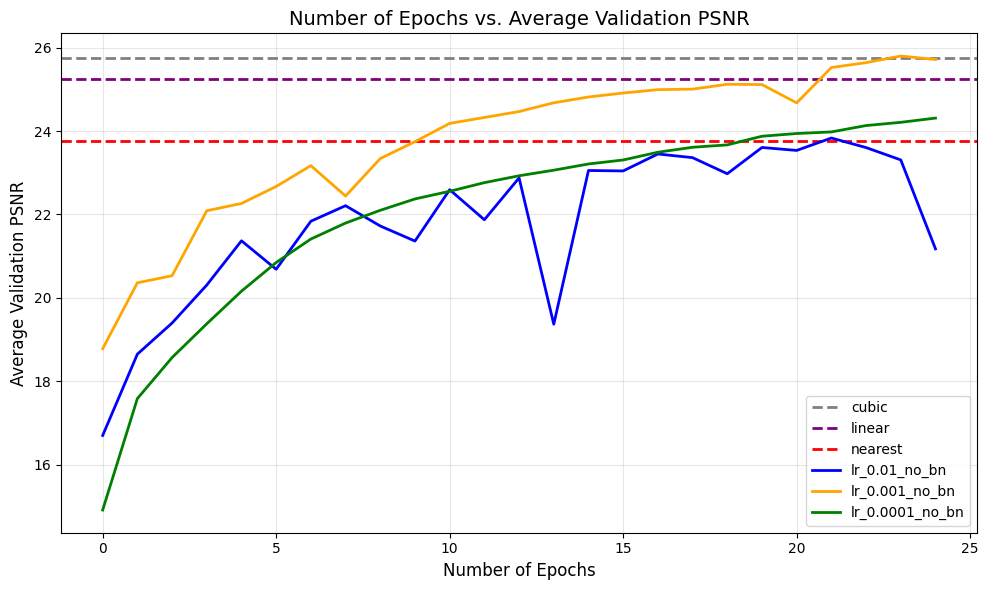

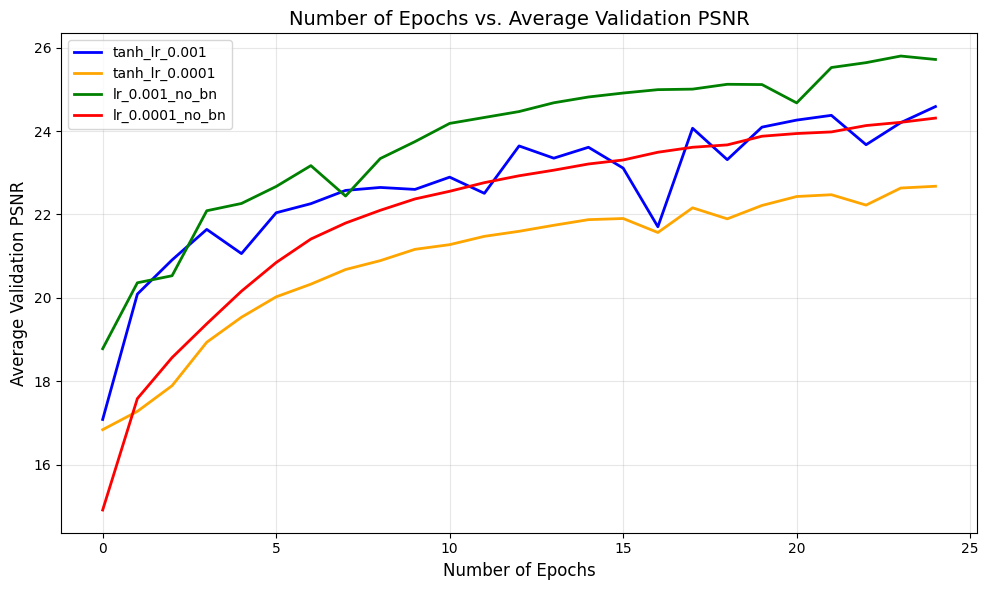

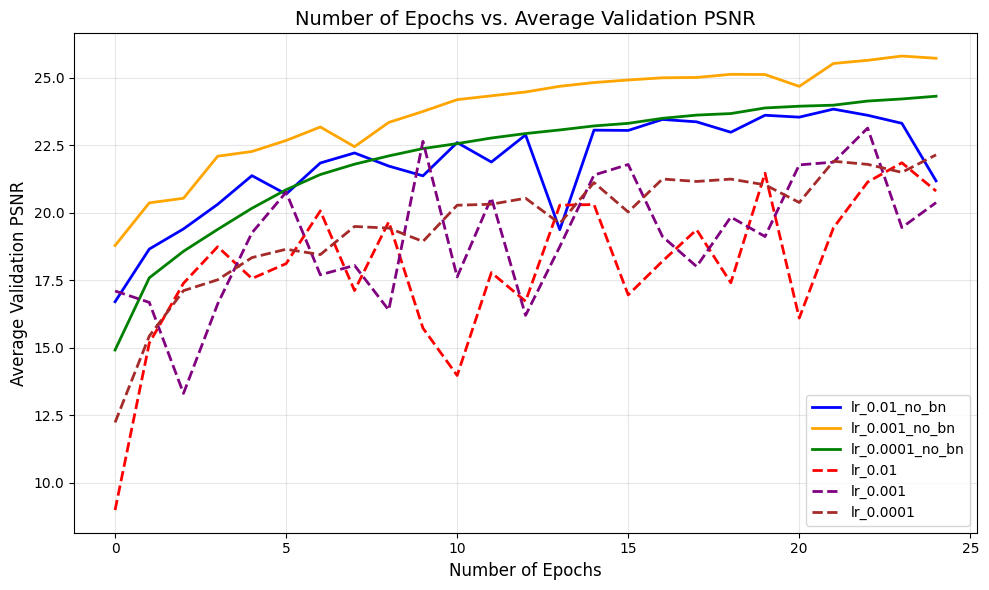

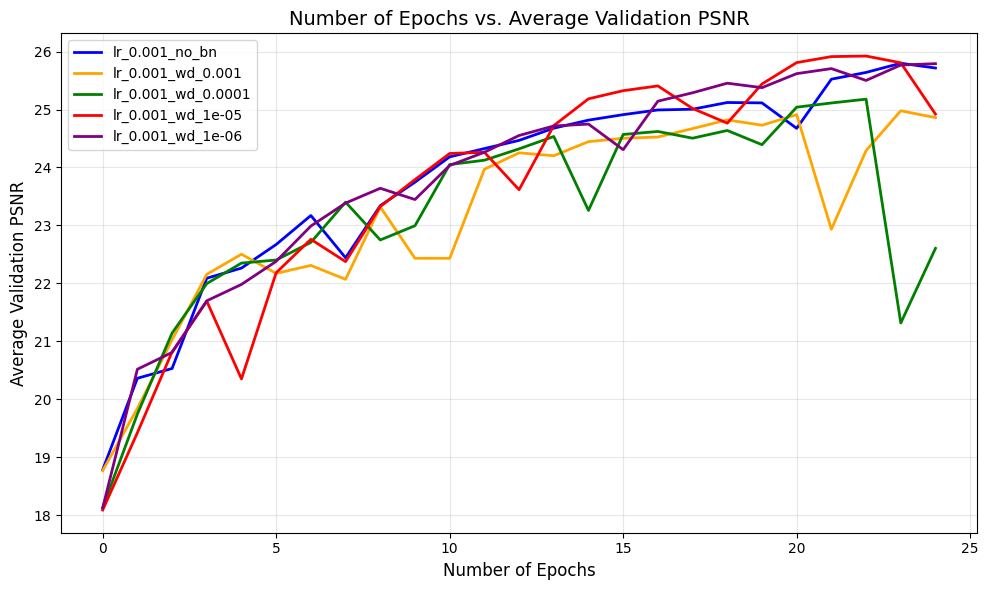


All figures saved!
- /content/figure3_learning_rate.png
- /content/figure4_tanh.png
- /content/figure5_batchnorm.png
- /content/figure6_regularization.png


In [51]:
run_all_experiments()